# Uncertainty Propagation for Annual Energy Needs (Simplified White-Box Model)

# Introduction
This notebook provides a concise introduction to uncertainty analysis within the context of building energy auditing.

The objective is to assess and guarantee building performance by propagating uncertainties through a simplified white-box energy model.

As discussed in the lecture, the workflow includes:

* Define a simple whitebox model
* Quantifying uncertainties in model parameters
* Performing Monte Carlo sampling (or variants such as Latin hypercube sampling)
* Propagating uncertainties through the model
* Analyzing and interpreting the resulting output distributions

This notebook serves as an introductory tutorial to these concepts and methods.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from typing import Dict, List, Tuple, Any
import statistics
# physical constants
RHO_AIR = 1.2       # kg/m3
CP_AIR = 1005       # J/(kg K)

## 1. Define the simplified white-box model
Here you should define a very simple model that computes the annual heating consumption of the building as follows:

$$ E_{heat} = \sum_{t=1}^{8760} max (\frac{UA(T_{set}-T_{ext}(t)) + \dot m c_p(T_{set}-T_{ext}(t)) - Q_{int}(t)}{COP}, 0) $$

Where:

$ U $: Global U-value of the envelope $ [W/m^2K] $

$ A $: Envelope area $ [m^2] $

$ T_{set} $: Heating setpoint $ [°C] $

$ COP $: Heating system coefficient of performance

$ Q_{int}(t) $: Internal gains at time step $ t $ $ [W] $

$ T_{ext}(t) $: Outdoor temperature for hour $ t $ $ [°C] $

In [2]:
def simulate_hourly_heating(params: Dict[str, float],
                            weather_t_out: np.ndarray,
                            gains_t_int: np.ndarray
                            ) -> Tuple[np.ndarray, np.ndarray]:
    """Simulate hourly heating loads for one year.

    Returns:
      Heat_needed: array of heat that must be delivered to meet setpoint (W)
      Heat_consumption: array of electrical power consumed by heating system (W)

    Model:
      UA_total = sum(U_i * A_i)
      Q_trans = UA_total * (T_set - T_out)        (W)
      Q_inf = rho * cp * (ACH/3600) * V * (T_set - T_out)  (W)
      Q_int given by gains_t_int * Qint_mult (W)
      Q_needed = Q_trans + Q_inf - Q_int
      delivered_heat = max(Q_needed, 0)
      electrical_power = delivered_heat / COP

    All arrays must have the same length (8760).
    """
    hours = weather_t_out.size
    # validate
    T_out = np.asarray(weather_t_out, dtype=float)
    Q_int_base = np.asarray(gains_t_int, dtype=float)
    T_set = params.get('T_set', 20.0)
    T_set_arr = np.ones(hours, dtype=float) * T_set

    # build UA
    UA_total = (params['U_wall'] * params['A_wall']
                + params['U_roof'] * params['A_roof']
                + params['U_win'] * params['A_win'])

    # transmission heat loss (W)
    Q_trans = UA_total * (T_set_arr - T_out)

    # infiltration heat loss (W)
    # ACH is in 1/h, convert to kg/s via volumetric flow.
    ACH = params['ACH']
    V = params['V']
    m_dot = (ACH * V) / 3600.0 * RHO_AIR  # kg/s
    Q_inf = m_dot * CP_AIR * (T_set_arr - T_out)  # W

    # internal gains
    Q_int = Q_int_base * params.get('Qint_mult', 1.0)

    # required delivered heat (W)
    Heat_needed = Q_trans + Q_inf - Q_int
    Heat_needed = np.maximum(Heat_needed, 0.0)
    Heat_needed[1776 : 6912] = 0.0  # Only heating season

    # electrical power assuming COP (COP>0)
    COP = params.get('COP', 3.0)
    # avoid division by zero
    cop = max(COP, 1e-3)
    Heat_consumption = Heat_needed / cop

    return Heat_needed, Heat_consumption


def annual_energy_kwh(params: Dict[str, float],
                       weather_t_out: np.ndarray,
                       gains_t_int: np.ndarray,
                       dt_hours: float = 1.0) -> float:
    """Compute annual electrical energy consumed for heating (kWh).

    dt_hours: timestep length in hours (default 1.0 for hourly)
    """
    _, electrical_power = simulate_hourly_heating(params, weather_t_out, gains_t_int)
    # energy in kWh
    E_kwh = np.sum(electrical_power) * dt_hours / 1000.0
    return float(E_kwh)

## 2. Parameter sampling method
To undergo uncertianty analysis and propagation you need a sampler that can sample from your degined uncertain parameters. 
In teh following cell implement a sampler function that can take as input the informatino of the parameters and their uncertainties and the number fo samples to generate for each parameter and that returns all the samples for all the parameters



In [3]:
def sample_parameters(specs: Dict[str, Dict[str, Any]], n: int, rng: np.random.Generator = None) -> List[Dict[str, float]]:
    """Sample parameter dictionaries according to a simple spec format.

    specs: mapping param_name -> {'dist': 'uniform'|'triangular'|'normal_clipped'|'lognormal', 'params': ...}
      - uniform: params = (low, high)
      - triangular: params = (left, mode, right)
      - normal_clipped: params = (mu, sigma, low, high)
      - lognormal: params = (mu_ln, sigma_ln)  (log-space)

    Returns list of n parameter dicts.
    """
    if rng is None:
        rng = np.random.default_rng()

    samples = []
    for i in range(n):
        p = {}
        for name, spec in specs.items():
            dist = spec.get('dist', 'uniform')
            pr = spec.get('params')
            if dist == 'uniform':
                low, high = pr
                val = rng.uniform(low, high)
            elif dist == 'triangular':
                left, mode, right = pr
                val = rng.triangular(left, mode, right)
            elif dist == 'normal_clipped':
                mu, sigma, low, high = pr
                val = rng.normal(mu, sigma)
                val = float(np.clip(val, low, high))
            elif dist == 'lognormal':
                mu_ln, sigma_ln = pr
                val = rng.lognormal(mean=mu_ln, sigma=sigma_ln)
            elif dist == 'constant':
                val = pr
            else:
                raise ValueError(f"Unknown dist '{dist}' for parameter '{name}'")
            p[name] = float(val)
        samples.append(p)
    return samples

## 3. Monte carlo engine
We also need a seperate function that can take all the generated samples and loop over the defined model and append all the results of all the generated samples and return them back.
In the following cell implement this function

In [4]:
def monte_carlo_annual_energy(param_samples: List[Dict[str, float]],
                            weather_t_out: np.ndarray,
                            gains_t_int: np.ndarray,
                            dt_hours: float = 1.0) -> np.ndarray:
    """Run annual_energy_kwh for each parameter sample and return array of energies (kWh).
    """
    energies = np.empty(len(param_samples), dtype=float)
    for i, p in enumerate(param_samples):
        energies[i] = annual_energy_kwh(p, weather_t_out, gains_t_int, dt_hours=dt_hours)
    return energies

## 4. Data loading
So now after having defined all the necessary blocks we can start laoding the data and launch some simulations. 
The data necessary to laucngh this simple project and which you can find in the csv file attached is only the external temperature. For this simple case we do not include other factors such as solar radiation.

In the following cell, load the data needed

In [6]:
df = pd.read_csv("data.csv", delimiter=";")
Text = df["Text"].values

## 5. Parameter specification and sampling utilities
The building under study is an old residential house built in 1920, about which very little detailed information is publicly available. While we know that it is equipped with a heat pump, no specific details about the system, such as its type, capacity, or efficiency are known, and it has been installed many years ago.

Despite the limited information, certain aspects of the building’s geometry are well-documented, including the following areas:

$$ A_{walls} = 60 m^2 $$
$$ A_{roof} = 35 m^2 $$
$$ A_{floor} = 35 m^2 $$

In the following cell, you will need to define all the model parameters and their uncertainties. You only know about the building geometry, the other parameters you need to estimate them and estimate the uncertainty about them.

In [7]:
# nominal internal gains profile: 1.0 kW during daytime (8-20), 0.2 kW otherwise
hours = len(Text)
gains = np.zeros(hours)
hours_in_day = np.arange(24)
mask = (hours_in_day >= 8) & (hours_in_day < 20)
# tile for whole year
gains_hour = np.where(mask, 1000.0, 200.0)  # W
gains = np.tile(gains_hour, int(hours/24))


# sampling specs (students would define these)
specs = {
    'U_wall': {'dist': 'triangular', 'params': (0.3, 0.4, 0.6)},
    'A_wall': {'dist': 'constant', 'params': 200.0},
    'U_roof': {'dist': 'uniform', 'params': (0.2, 0.5)},
    'A_roof': {'dist': 'constant', 'params': 100.0},
    'U_win': {'dist': 'uniform', 'params': (1.2, 2.5)},
    'A_win': {'dist': 'constant', 'params': 22.5},
    'ACH': {'dist': 'triangular', 'params': (0.3, 0.6, 1.0)},
    'V': {'dist': 'normal_clipped', 'params': (600.0, 30.0, 540.0, 660.0)},
    'COP': {'dist': 'normal_clipped', 'params': (3.0, 0.3, 2.0, 4.0)},
    'Qint_mult': {'dist': 'uniform', 'params': (0.7, 1.3)},
    'T_set': {'dist': 'uniform', 'params': (19.0, 21.0)}
}

## 6. Run uncertainty analysis
After defining all the necessary functions and defined the uncertainty on your case study, now you can laucnh the uncertainty analysis

In [8]:
rng = np.random.default_rng(42)
N = 500
samples = sample_parameters(specs, N, rng=rng)
energies = monte_carlo_annual_energy(samples, Text, gains)

## 7. Statistics 
Define some statistical measured to describe the distribution of your output

In [9]:
mean_E = float(np.mean(energies))
p50 = float(np.percentile(energies, 50))
p90 = float(np.percentile(energies, 90))

print(f"Monte Carlo runs: {N}")
print(f"Mean annual heating energy (kWh): {mean_E:0.1f}")
print(f"P50: {p50:0.1f} kWh, P90: {p90:0.1f} kWh")

Monte Carlo runs: 500
Mean annual heating energy (kWh): 3411.8
P50: 3338.7 kWh, P90: 4229.1 kWh


## 8. Visualisation
Plot the distribution of your output and carry out some analysis. If this distribution was obtained after some renovation measures applied, what would be the value of energy consumption that you could communicate to be on the safe side

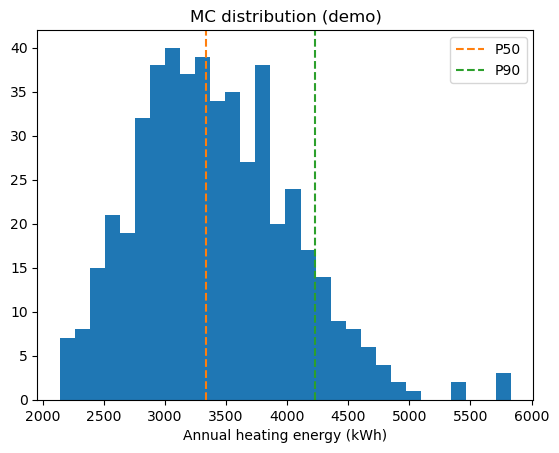

In [10]:

# simple histogram if matplotlib is available
try:
    import matplotlib.pyplot as plt
    plt.hist(energies, bins=30, density=False)
    plt.xlabel('Annual heating energy (kWh)')
    plt.title('MC distribution (demo)')
    plt.axvline(p50, color='C1', linestyle='--', label='P50')
    plt.axvline(p90, color='C2', linestyle='--', label='P90')
    plt.legend()
    plt.show()
except Exception:
    pass